# Bài 2 — Câu 3: Hệ số tương quan Pearson

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Dữ liệu theo `TaiLieuLab02.pdf`. Mỗi notebook chạy độc lập.

Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Số mẫu trước xử lý: train=32561, test=16281
Số mẫu sau xử lý: train=30162, test=15060; gộp=45222
Ma trận Pearson:
                  age  education-num  capital-gain  capital-loss  hours-per-week
age             1.000          0.038         0.080         0.059           0.102
education-num   0.038          1.000         0.127         0.082           0.146
capital-gain    0.080          0.127         1.000        -0.032           0.084
capital-loss    0.059          0.082        -0.032         1.000           0.054
hours-per-week  0.102          0.146         0.084         0.054           1.000


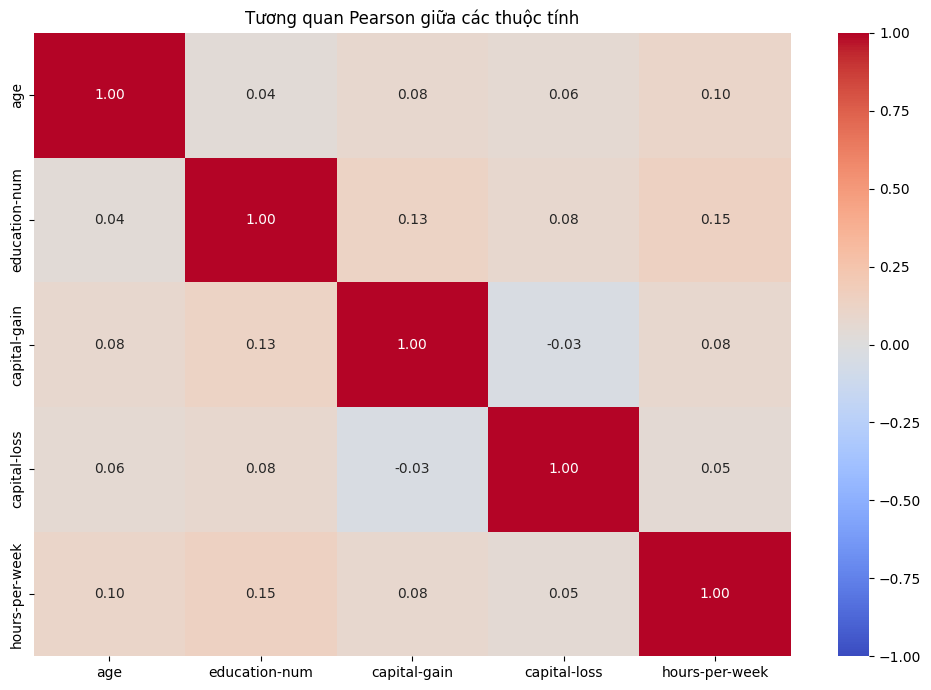

Các cột có thể loại vì tương quan rất cao: Không có


In [1]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'adult'
train = pd.read_csv(get_file('adult.data.csv'), skipinitialspace=True)
test = pd.read_csv(get_file('adult.test.csv'), skipinitialspace=True)
raw_train, raw_test = len(train), len(test)
for df in (train, test):
    df.replace(r'^\s*\?\s*$', np.nan, regex=True, inplace=True)
    for col in df.select_dtypes(include='object'):
        df[col] = df[col].str.strip()
    df['income'] = df['income'].str.rstrip('.')
train = train.dropna().drop(columns=['fnlwgt']).reset_index(drop=True)
test = test.dropna().reset_index(drop=True)
n_train, n_test = len(train), len(test)
data = pd.concat([train, test], ignore_index=True)
print(f'Số mẫu trước xử lý: train={raw_train}, test={raw_test}')
print(f'Số mẫu sau xử lý: train={n_train}, test={n_test}; gộp={len(data)}')

# Pearson tính trên các cột số; không đưa nhãn quyết định vào phân tích tương quan thuộc tính.
numeric = data.drop(columns=['income']).select_dtypes(include=np.number)
corr = numeric.corr(method='pearson')
print('Ma trận Pearson:')
print(corr.round(3).to_string())
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Tương quan Pearson giữa các thuộc tính')
plt.tight_layout(); plt.show()
# Ngưỡng tham khảo |r| > 0.90, xét một nửa tam giác trên để tránh trùng lặp.
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if any(upper[c] > 0.90)]
print('Các cột có thể loại vì tương quan rất cao:', drop_corr if drop_corr else 'Không có')
